# CÀI ĐẶT THUẬT TOÁN CHUẨN HÓA VÀ HỒI QUY

In [31]:
import numpy as np

class StandardScalerNumpy:
    def __init__(self):
        self.mean = None
        self.std = None

    def fit(self, X):
        self.mean = np.mean(X, axis=0)
        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1.0
        return self

    def transform(self, X):
        return (X - self.mean) / self.std

    def fit_transform(self, X):
        return self.fit(X).transform(X)

class LinearRegressionNumpy:
    def __init__(self):
        self.w = None
        self.b = None

    def fit(self, X, y):
        n_samples = X.shape[0]
        X_b = np.hstack([np.ones((n_samples, 1)), X])
        beta = np.dot(np.linalg.pinv(np.dot(X_b.T, X_b)), np.dot(X_b.T, y))
        self.b = beta[0]
        self.w = beta[1:]

    def predict(self, X):
        return np.dot(X, self.w) + self.b

def evaluate_regression(y_true, y_pred):
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y_true - y_pred))
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1.0 - (ss_res / ss_tot) if ss_tot != 0 else 0.0
    return mse, rmse, mae, r2

# TIỀN XỬ LÝ VÀ CHUẨN HÓA DỮ LIỆU

In [32]:
import pandas as pd

DATA_PATH = "../../Lab01/2/sp500_yahoo.csv"
df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

df['Return'] = df['Close'].pct_change()
df['Vol_5d'] = df['Return'].rolling(5).std()
df['MA5'] = df['Close'].rolling(5).mean()
df['MA20'] = df['Close'].rolling(20).mean()
df['Next_Close'] = df['Close'].shift(-1)
df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

feature_cols = ['Open', 'High', 'Low', 'Close', 'Volume', 'Return', 'MA5', 'MA20', 'Vol_5d']
X = df[feature_cols].values
y = df['Next_Close'].values

split_idx = int(len(X) * 0.8)
X_train_raw, X_test_raw = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

scaler = StandardScalerNumpy()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

print(f"X_train shape: {X_train_scaled.shape}, X_test shape: {X_test_scaled.shape}")

X_train shape: (19826, 9), X_test shape: (4957, 9)


# HUẤN LUYỆN VÀ SO SÁNH MÔ HÌNH

In [33]:
model_raw = LinearRegressionNumpy()
model_raw.fit(X_train_raw, y_train)
y_pred_raw = model_raw.predict(X_test_raw)
mse_raw, rmse_raw, mae_raw, r2_raw = evaluate_regression(y_test, y_pred_raw)

model_scaled = LinearRegressionNumpy()
model_scaled.fit(X_train_scaled, y_train)
y_pred_scaled = model_scaled.predict(X_test_scaled)
mse_sc, rmse_sc, mae_sc, r2_sc = evaluate_regression(y_test, y_pred_scaled)

print("=" * 60)
print("SO SÁNH HIỆU NĂNG (Bài 2 - Chuẩn hóa dữ liệu):")
print(f"- Dữ liệu gốc       : MSE={mse_raw:.4f}, RMSE={rmse_raw:.4f}, MAE={mae_raw:.4f}, R2={r2_raw:.4f}")
print(f"- Dữ liệu chuẩn hóa : MSE={mse_sc:.4f}, RMSE={rmse_sc:.4f}, MAE={mae_sc:.4f}, R2={r2_sc:.4f}")
print("=" * 60)

SO SÁNH HIỆU NĂNG (Bài 2 - Chuẩn hóa dữ liệu):
- Dữ liệu gốc       : MSE=1562.3543, RMSE=39.5266, MAE=25.6059, R2=0.9995
- Dữ liệu chuẩn hóa : MSE=1170.2773, RMSE=34.2093, MAE=21.0166, R2=0.9996


# VẼ ĐỒ THỊ SO SÁNH TRỌNG SỐ

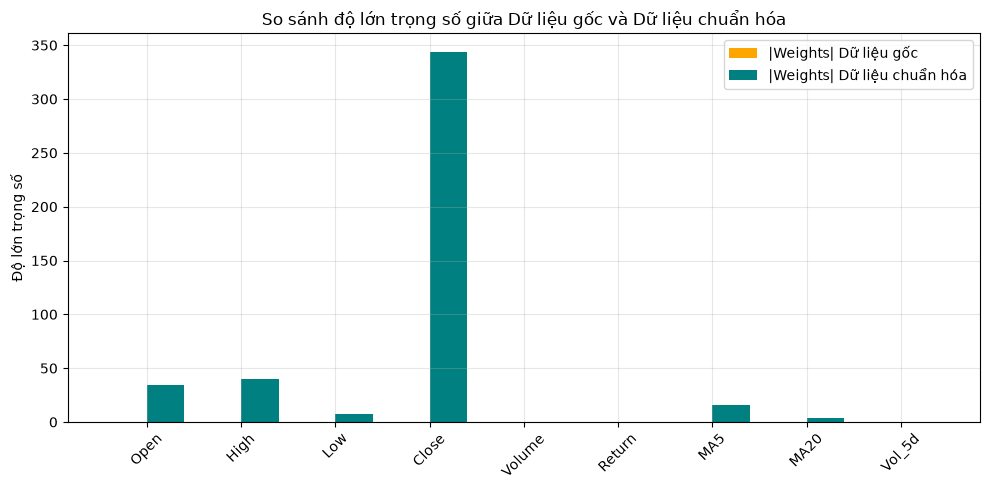

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
x = np.arange(len(feature_cols))
plt.bar(x - 0.2, np.abs(model_raw.w), width=0.4, label='|Weights| Dữ liệu gốc', color='orange')
plt.bar(x + 0.2, np.abs(model_scaled.w), width=0.4, label='|Weights| Dữ liệu chuẩn hóa', color='teal')
plt.xticks(x, feature_cols, rotation=45)
plt.ylabel("Độ lớn trọng số")
plt.title("So sánh độ lớn trọng số giữa Dữ liệu gốc và Dữ liệu chuẩn hóa")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()